# Deteksi Transaksi Fraud Kartu Kredit Menggunakan Metode Klasifikasi

**Notebook:** Business Understanding, Data Gathering, EDA, Data Cleaning, dan Preprocessing
**Mata kuliah:** Data Science (IF-A) | **Dosen pengampu:** Dhimas Arief Dharmawan

| No | Nama | NIM |
|----|------|-----|
| 1 | Farabian Nabil Alauzi | 123240058 |
| 2 | Waladi Lintang Novianto | 123240065 |
| 3 | Raflin Madani | 123240178 |
| 4 | Raihan Buono Putra | 123240090 |

Program Studi Informatika, Fakultas Teknik Industri, Universitas Pembangunan Nasional "Veteran" Yogyakarta, 2026

---

# 1. Data Gathering

## 1.1 Sumber Data dan Lisensi

Dataset yang digunakan adalah **Credit Card Fraud Detection** dari Kaggle, dipublikasikan oleh Machine Learning Group, Universite Libre de Bruxelles (ULB). Isinya transaksi kartu kredit pemegang kartu di Eropa selama dua hari pada September 2013. Informasi lisensi pada Kaggle: *Database: Open Database, Contents: Database Contents*.

- Tautan: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Dataset lengkap: 284.807 transaksi (492 fraud, 284.315 normal), 31 kolom.

## 1.2 Dataset Kerja (`creditcard_1000.csv`)

Untuk tugas ini digunakan subset **1.000 transaksi**: seluruh 492 transaksi fraud dari dataset lengkap ditambah 508 transaksi normal yang dipilih acak (`random_state=42`). Baris duplikat bawaan dataset asli **tidak dihapus** agar dapat dinilai pada tahap cleaning. Subset dibuat dengan kode berikut (tidak dijalankan di notebook ini karena memerlukan `creditcard.csv` lengkap):

```python
df_full = pd.read_csv("creditcard.csv")
fraud = df_full[df_full["Class"] == 1]
normal = df_full[df_full["Class"] == 0].sample(n=1000 - len(fraud), random_state=42)
pd.concat([fraud, normal]).sort_index().to_csv("creditcard_1000.csv", index=False)
```

## 1.3 Data Dictionary

| No | Kolom | Tipe | Deskripsi |
|----|-------|------|-----------|
| 1 | `Time` | Numerik | Waktu transaksi dalam detik sejak transaksi pertama dalam dataset |
| 2-29 | `V1` - `V28` | Numerik | Fitur hasil transformasi PCA (dianonimkan untuk menjaga kerahasiaan) |
| 30 | `Amount` | Numerik | Nominal transaksi (satuan mata uang tidak dinyatakan pada file) |
| 31 | `Class` | Numerik (biner) | Variabel target: 0 = transaksi normal, 1 = fraud |

## IMPORT Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler # Scalling
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## IMPORT DATA

In [2]:
df = pd.read_csv("creditcard_1000.csv")
print(df.head(5))
print("\nInformasi Umum Dataset: ")
df.info()

     Time        V1        V2        V3        V4        V5        V6  \
0   406.0 -2.312227  1.951992 -1.609851  3.997906 -0.522188 -1.426545   
1   472.0 -3.043541 -3.157307  1.088463  2.288644  1.359805 -1.064823   
2   607.0  1.038261 -0.301415  0.910167  0.863872 -0.741702  0.090125   
3   861.0 -0.945987  1.232753  0.820313  0.311064  0.981736  0.935188   
4  1308.0 -1.379848  0.536720  2.647870  1.408111  0.126442  0.986525   

         V7        V8        V9  ...       V21       V22       V23       V24  \
0 -2.537387  1.391657 -2.770089  ...  0.517232 -0.035049 -0.465211  0.320198   
1  0.325574 -0.067794 -0.270953  ...  0.661696  0.435477  1.375966 -0.293803   
2 -0.409753  0.076723  0.684990  ...  0.134996  0.554309 -0.138944  0.168500   
3  0.566926 -0.008604 -0.621912  ...  0.124922  0.284644 -0.197951 -1.326061   
4  0.960251 -0.629717  1.729173  ... -0.666874 -0.343574  0.022138  0.093532   

        V25       V26       V27       V28  Amount  Class  
0  0.044519  0.177840

# 2. Exploratory Data Analysis (EDA)

## 2.1 Gambaran Umum Dataset

In [3]:
# Cek Dataset
print(f"Ukuran Dataset: {df.shape} \n")

print(f"Tipe Data :")
df.info()

print("\nStatistik Deskriptif: ")
display(df.describe().T)

Ukuran Dataset: (1000, 31) 

Tipe Data :
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     

,count,mean,std,min,25%,50%,75%,max
Time,1000.0,88105.316000,48076.754070,406.000000,46099.750000,81348.000000,134766.750000,171917.000000
V1,1000.0,-2.269096,5.490748,-30.552380,-2.732232,-0.741705,1.134074,2.351891
V2,1000.0,1.782844,3.659953,-8.402154,-0.173693,0.903714,2.777569,22.057729
V3,1000.0,-3.479627,6.168222,-31.103685,-5.049001,-1.326710,0.242719,3.143387
V4,1000.0,2.224461,3.198678,-4.519509,-0.177790,1.275632,4.173330,12.114672
V5,1000.0,-1.521588,4.177193,-22.105532,-1.736819,-0.336980,0.493738,11.095089
V6,1000.0,-0.715315,1.718498,-6.406267,-1.572363,-0.664051,0.080004,6.474115
V7,1000.0,-2.733041,5.810310,-43.557242,-3.028330,-0.608816,0.288919,5.802537
V8,1000.0,0.284916,4.821946,-41.044261,-0.229344,0.137477,0.855025,20.007208
V9,1000.0,-1.253420,2.332128,-13.434066,-2.331368,-0.695574,0.194952,5.232322


## 2.2 Distribusi Kelas

       Jumlah  Persentase (%)
Class                        
0         508            50.8
1         492            49.2


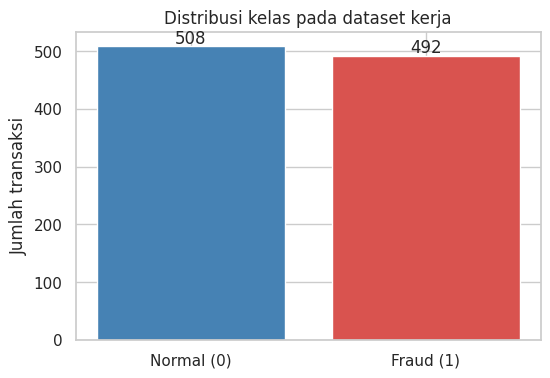

In [4]:
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"Jumlah": class_counts, "Persentase (%)": class_pct.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4682B4", "#D9534F"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 5, int(b.get_height()), ha="center")
ax.set_ylabel("Jumlah transaksi")
ax.set_title("Distribusi kelas pada dataset kerja")
plt.show()

Dataset kerja hampir seimbang karena merupakan hasil pengambilan **seluruh fraud** dan **sebagian transaksi normal**. Pada dataset lengkap proporsi fraud hanya sekitar 0,17%, jadi hasil EDA dan model dari subset ini tidak boleh langsung dianggap mewakili kondisi nyata.

## 2.3 Distribusi Nilai Transaksi (`Amount`)

       count    mean     std  min   25%    50%     75%      max
Class                                                          
0      508.0   81.44  177.45  0.0  4.14  19.98   70.16  1464.94
1      492.0  122.21  256.68  0.0  1.00   9.25  105.89  2125.87

Persentil ke-99 Amount: 1219.12


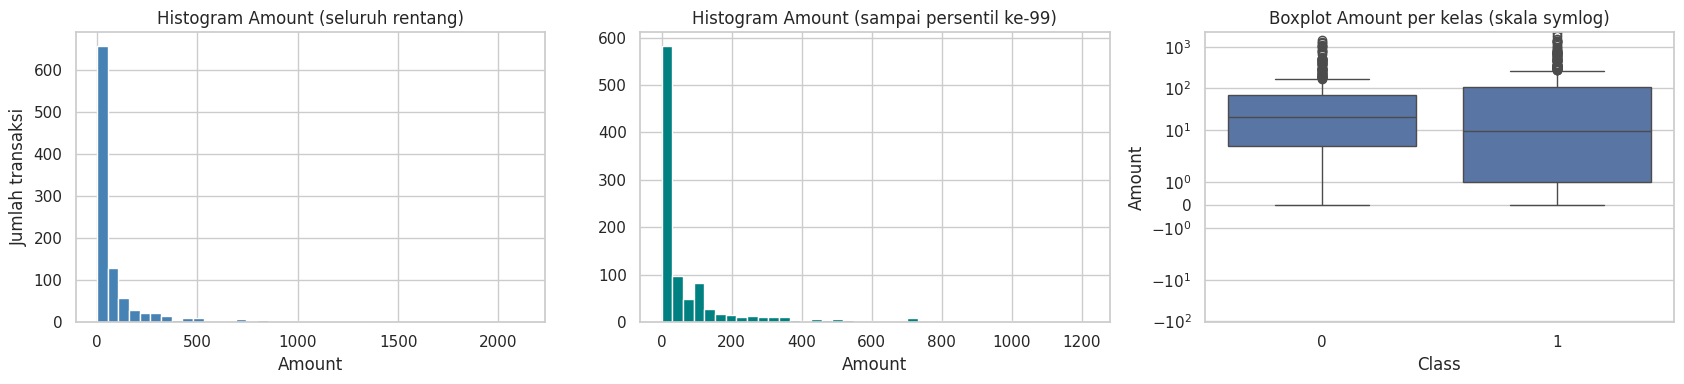

In [5]:
print(df.groupby("Class")["Amount"].describe().round(2))

p99 = df["Amount"].quantile(0.99)
print(f"\nPersentil ke-99 Amount: {p99:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(df["Amount"], bins=40, color="#4682B4")
axes[0].set_title("Histogram Amount (seluruh rentang)")
axes[0].set_xlabel("Amount"); axes[0].set_ylabel("Jumlah transaksi")

axes[1].hist(df.loc[df["Amount"] <= p99, "Amount"], bins=40, color="teal")
axes[1].set_title("Histogram Amount (sampai persentil ke-99)")
axes[1].set_xlabel("Amount")

sns.boxplot(data=df, x="Class", y="Amount", ax=axes[2])
axes[2].set_yscale("symlog")
axes[2].set_title("Boxplot Amount per kelas (skala symlog)")
plt.tight_layout()
plt.show()

Distribusi `Amount` berekor panjang ke kanan (rata-rata jauh di atas median) sehingga sensitif terhadap nilai ekstrem. Hal ini perlu diperhatikan pada tahap penskalaan.

## 2.4 Distribusi Waktu (`Time`)

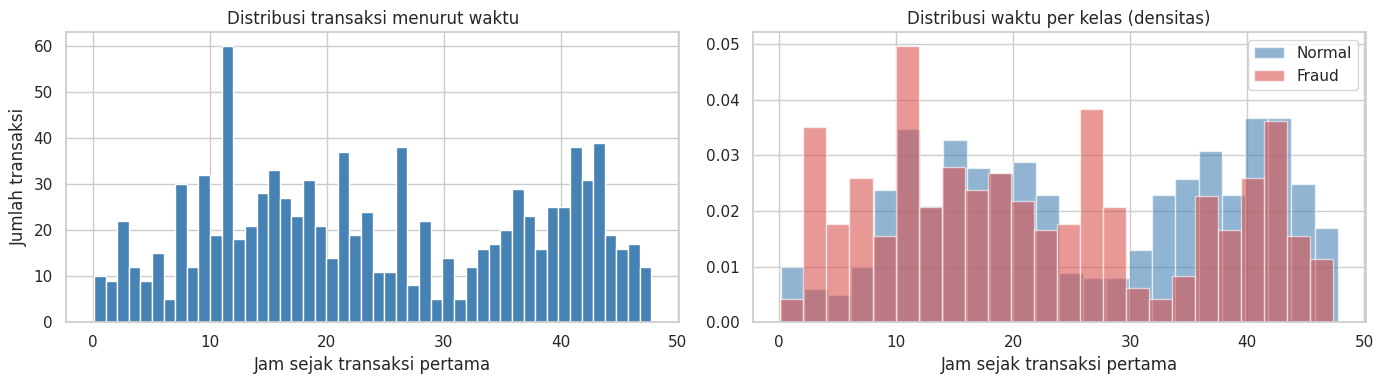

In [6]:
df_time = df.assign(Jam=df["Time"] / 3600)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_time["Jam"], bins=48, color="#4682B4")
axes[0].set_title("Distribusi transaksi menurut waktu")
axes[0].set_xlabel("Jam sejak transaksi pertama"); axes[0].set_ylabel("Jumlah transaksi")

for kelas, warna, label in [(0, "#4682B4", "Normal"), (1, "#D9534F", "Fraud")]:
    axes[1].hist(df_time.loc[df_time["Class"] == kelas, "Jam"], bins=24, alpha=0.6,
                 color=warna, label=label, density=True)
axes[1].set_title("Distribusi waktu per kelas (densitas)")
axes[1].set_xlabel("Jam sejak transaksi pertama"); axes[1].legend()
plt.tight_layout()
plt.show()

## 2.5 Korelasi Fitur dengan Target

10 fitur dengan korelasi absolut terbesar terhadap Class:
V14   -0.751
V4     0.713
V11    0.687
V12   -0.685
V10   -0.632
V16   -0.600
V3    -0.567
V17   -0.562
V9    -0.561
V2     0.495
Name: Class, dtype: float64


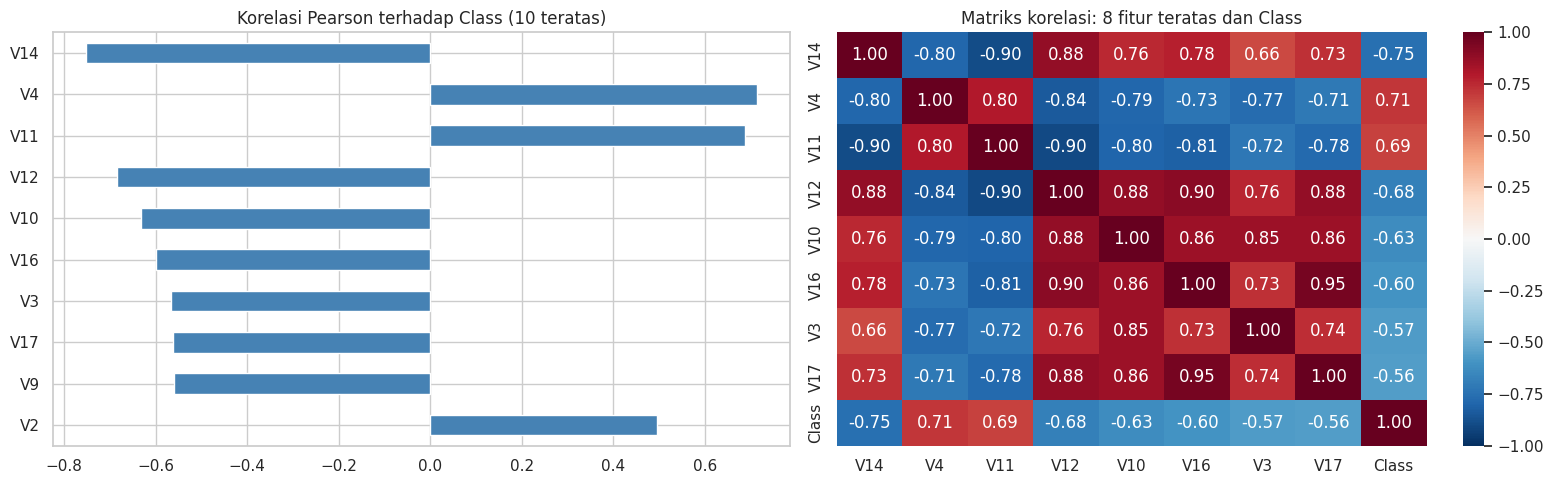

In [7]:
corr_target = df.corr()["Class"].drop("Class").sort_values(key=np.abs, ascending=False)
print("10 fitur dengan korelasi absolut terbesar terhadap Class:")
print(corr_target.head(10).round(3))

top_feats = corr_target.head(8).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr_target.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#4682B4")
axes[0].set_title("Korelasi Pearson terhadap Class (10 teratas)")

sns.heatmap(df[top_feats + ["Class"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Matriks korelasi: 8 fitur teratas dan Class")
plt.tight_layout()
plt.show()

Korelasi bersifat statistik (hubungan linear), bukan bukti sebab-akibat maupun ukuran kepentingan fitur pada model. Karena `V1`-`V28` hasil PCA, makna bisnisnya tidak dapat ditentukan. Perlu diingat bahwa nilai korelasi pada subset yang hampir seimbang ini akan lebih besar daripada pada dataset lengkap.

## 2.6 Perbandingan Distribusi Fitur Teratas per Kelas

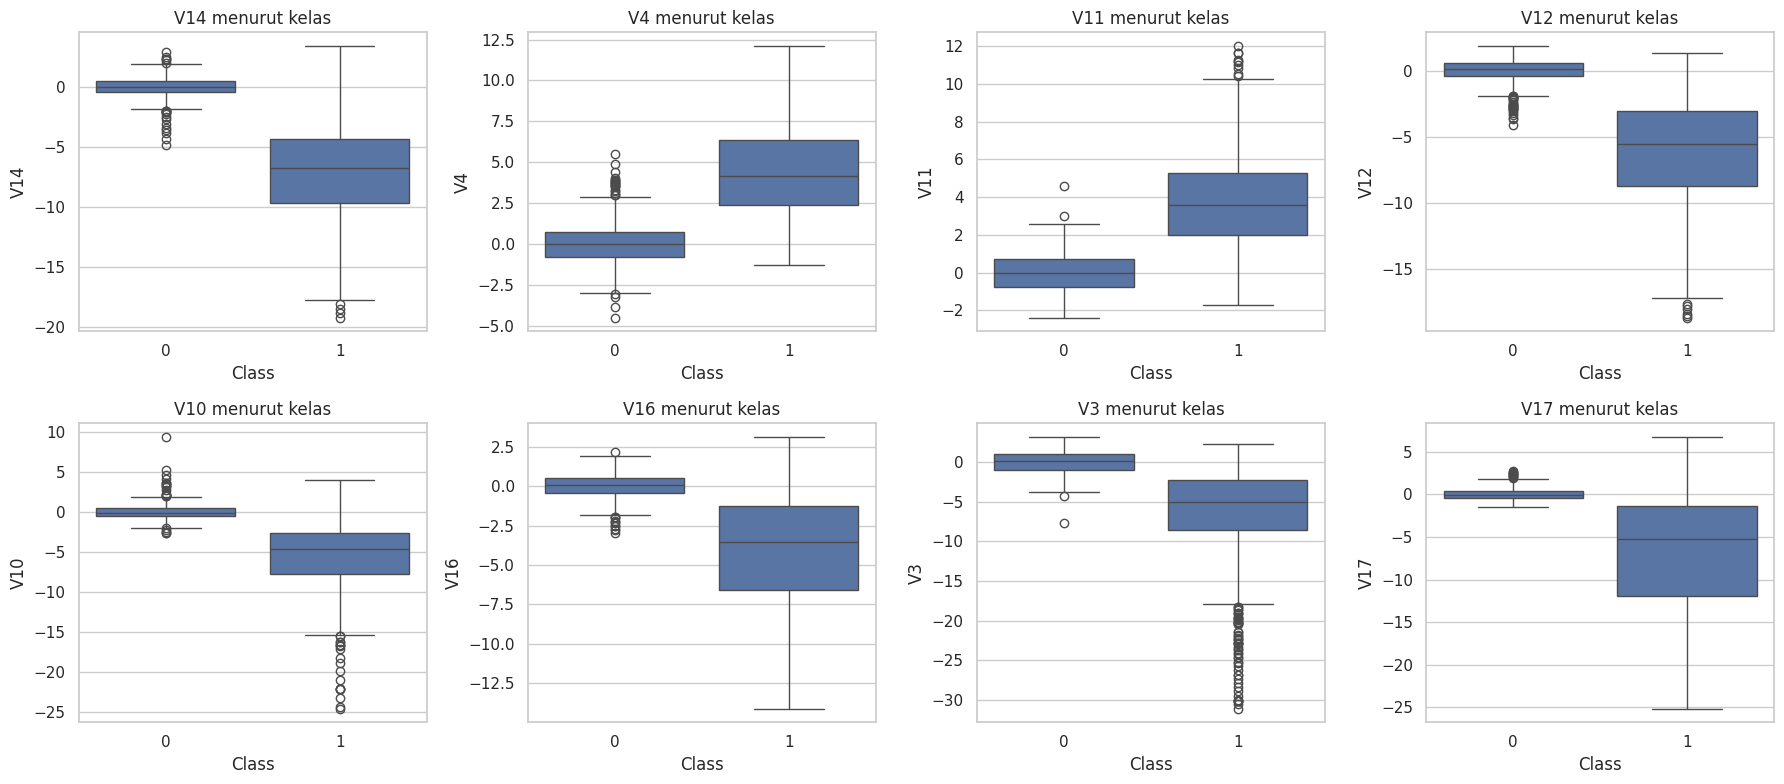

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feat in zip(axes.ravel(), top_feats):
    sns.boxplot(data=df, x="Class", y=feat, ax=ax)
    ax.set_title(f"{feat} menurut kelas")
plt.tight_layout()
plt.show()

## 2.7 Pemeriksaan Kualitas Data (Missing Value dan Duplikat)

In [9]:
# Tangani Data Kotor
print("\nMissing Values: ")
print(df.isnull().sum())

print(f"\nData Duplikat: {df.duplicated().sum()}")


Missing Values: 
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Duplikat: 19


## 2.8 Pemeriksaan Kandidat Outlier (Metode IQR)

,Fitur,Jumlah outlier,Persentase (%),Batas bawah,Batas atas
0,V8,167,16.7,-1.856,2.482
1,V27,157,15.7,-0.837,1.226
2,V28,138,13.8,-0.456,0.608
3,V23,134,13.4,-0.886,0.840
4,V5,127,12.7,-5.083,3.840
5,V7,125,12.5,-8.004,5.265
6,V20,125,12.5,-1.163,1.437
7,Amount,116,11.6,-146.760,248.040
8,V21,110,11.0,-1.396,1.871
9,V18,102,10.2,-4.864,3.476


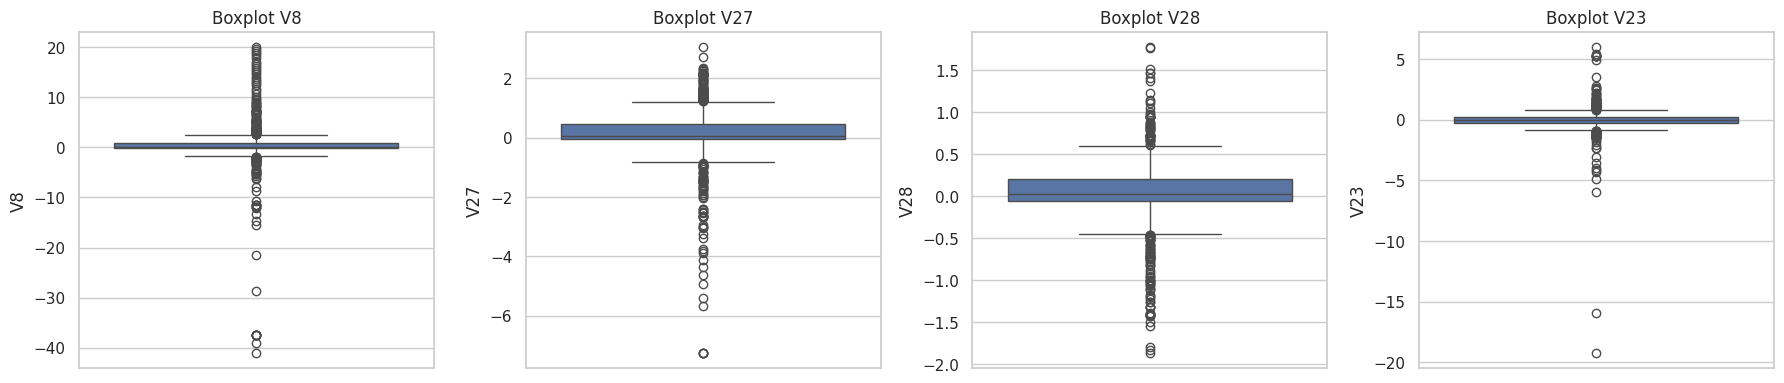

In [10]:
def hitung_outlier_iqr(data, kolom):
    q1, q3 = data[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (data[kolom] < batas_bawah) | (data[kolom] > batas_atas)
    return mask.sum(), batas_bawah, batas_atas

fitur = [c for c in df.columns if c != "Class"]
ringkas = []
for k in fitur:
    n, lo, hi = hitung_outlier_iqr(df, k)
    ringkas.append({"Fitur": k, "Jumlah outlier": n, "Persentase (%)": round(n / len(df) * 100, 2),
                    "Batas bawah": round(lo, 3), "Batas atas": round(hi, 3)})

tabel_outlier = pd.DataFrame(ringkas).sort_values("Jumlah outlier", ascending=False)
display(tabel_outlier.head(10).reset_index(drop=True))

top_out = tabel_outlier["Fitur"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, top_out):
    sns.boxplot(y=df[f], ax=ax)
    ax.set_title(f"Boxplot {f}")
plt.tight_layout()
plt.show()

# 3. Data Cleaning

Cleaning dilakukan pada salinan data (`df_clean`) agar data asli (`df`) tetap tersedia sebagai pembanding.

## 3.1 Penanganan Missing Value

In [11]:
df_clean = df.copy()

total_missing = df_clean.isnull().sum().sum()
print(f"Total missing value: {total_missing}")

if total_missing > 0:
    # Penanganan generik bila ada nilai kosong: imputasi median untuk fitur numerik
    kolom_kosong = df_clean.columns[df_clean.isnull().any()]
    for k in kolom_kosong:
        df_clean[k] = df_clean[k].fillna(df_clean[k].median())
    print("Missing value diisi dengan median kolom:", list(kolom_kosong))
else:
    print("Tidak ada missing value, tidak diperlukan imputasi atau penghapusan baris.")

Total missing value: 0
Tidak ada missing value, tidak diperlukan imputasi atau penghapusan baris.


## 3.2 Penanganan Data Duplikat

Karena tidak ada ID transaksi, baris yang identik pada seluruh kolom tidak pasti merupakan kesalahan pencatatan. Namun baris identik yang tersebar di data latih dan data uji menimbulkan **kebocoran data (*data leakage*)** dan membuat performa model tampak lebih baik dari seharusnya. Karena itu duplikat diperiksa dulu, lalu dihapus (menyisakan kemunculan pertama).

In [12]:
mask_dup_semua = df_clean.duplicated(keep=False)   # semua salinan, termasuk yang pertama
mask_dup_lebih = df_clean.duplicated(keep="first") # hanya salinan kelebihan

print(f"Baris yang punya kembaran (semua salinan): {mask_dup_semua.sum()}")
print(f"Baris duplikat kelebihan yang akan dihapus: {mask_dup_lebih.sum()}")
print("\nDistribusi kelas pada baris duplikat kelebihan:")
print(df_clean.loc[mask_dup_lebih, "Class"].value_counts())

print("\nContoh baris duplikat:")
display(df_clean[mask_dup_semua].sort_values(["Time", "Amount"]).head(8))

Baris yang punya kembaran (semua salinan): 32
Baris duplikat kelebihan yang akan dihapus: 19

Distribusi kelas pada baris duplikat kelebihan:
Class
1    19
Name: count, dtype: int64

Contoh baris duplikat:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
410,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
411,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
412,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
413,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
414,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
415,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
512,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1
513,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,...,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1


In [13]:
sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Jumlah baris sebelum : {sebelum}")
print(f"Jumlah baris sesudah : {len(df_clean)}")
print(f"Duplikat tersisa     : {df_clean.duplicated().sum()}")
print("\nDistribusi kelas setelah penghapusan duplikat:")
print(df_clean["Class"].value_counts().sort_index())

Jumlah baris sebelum : 1000
Jumlah baris sesudah : 981
Duplikat tersisa     : 0

Distribusi kelas setelah penghapusan duplikat:
Class
0    508
1    473
Name: count, dtype: int64


Seluruh duplikat berada pada kelas fraud, sehingga penghapusan duplikat mengurangi jumlah sampel fraud, sedangkan jumlah transaksi normal tidak berubah.

## 3.3 Penanganan Outlier

Kandidat outlier **tidak dihapus**. Pada kasus fraud, transaksi dengan nilai ekstrem justru bisa merupakan fraud yang ingin dideteksi, dan fitur `V1`-`V28` hasil PCA secara alami memiliki ekor distribusi yang panjang. Strategi yang dipakai: outlier dipertahankan, dan pengaruhnya pada `Amount` dikendalikan melalui **penskalaan robust** pada tahap preprocessing.

In [14]:
# Periksa sebaran kandidat outlier Amount menurut kelas
n_out, lo, hi = hitung_outlier_iqr(df_clean, "Amount")
mask_out_amount = (df_clean["Amount"] < lo) | (df_clean["Amount"] > hi)
print(f"Batas IQR Amount: [{lo:.2f}, {hi:.2f}]")
print(f"Kandidat outlier Amount: {n_out} ({n_out / len(df_clean) * 100:.2f}%)")
print("\nKelas pada kandidat outlier Amount:")
print(df_clean.loc[mask_out_amount, "Class"].value_counts())

# Transaksi bernilai nol
n_nol = (df_clean["Amount"] == 0).sum()
print(f"\nTransaksi dengan Amount = 0: {n_nol}")
print(df_clean.loc[df_clean["Amount"] == 0, "Class"].value_counts().rename("Jumlah per kelas"))

Batas IQR Amount: [-146.76, 248.04]
Kandidat outlier Amount: 113 (11.52%)

Kelas pada kandidat outlier Amount:
Class
1    71
0    42
Name: count, dtype: int64

Transaksi dengan Amount = 0: 31
Class
1    25
0     6
Name: Jumlah per kelas, dtype: int64


Transaksi dengan `Amount = 0` juga dipertahankan. Nilai nol tidak otomatis salah, misalnya bisa berupa verifikasi kartu, dan tidak ada informasi untuk menyimpulkan bahwa itu kesalahan data.

## 3.4 Validasi Hasil Cleaning

In [15]:
print(f"Ukuran data asli    : {df.shape}")
print(f"Ukuran data bersih  : {df_clean.shape}")
print(f"Missing value       : {df_clean.isnull().sum().sum()}")
print(f"Duplikat            : {df_clean.duplicated().sum()}")

ringkasan_cleaning = pd.DataFrame({
    "Sebelum": df["Class"].value_counts().sort_index(),
    "Sesudah": df_clean["Class"].value_counts().sort_index(),
})
ringkasan_cleaning.index = ["Normal (0)", "Fraud (1)"]
display(ringkasan_cleaning)

Ukuran data asli    : (1000, 31)
Ukuran data bersih  : (981, 31)
Missing value       : 0
Duplikat            : 0


,Sebelum,Sesudah
Normal (0),508,508
Fraud (1),492,473


# 4. Preprocessing

Urutan langkah dibuat agar bebas kebocoran data: **pisahkan data latih dan uji dahulu, baru lakukan penskalaan** dengan parameter yang dipelajari hanya dari data latih.

## 4.1 Pemisahan Fitur dan Target

In [16]:
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

Bentuk X: (981, 30) | Bentuk y: (981,)


## 4.2 Pembagian Data Latih dan Uji (Stratified)

Pembagian 80:20 dengan `stratify=y` agar proporsi fraud pada data latih dan uji sama dengan data keseluruhan.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Data latih: {X_train.shape[0]} baris | Data uji: {X_test.shape[0]} baris\n")
dist = pd.DataFrame({
    "Seluruh data": y.value_counts(normalize=True).sort_index() * 100,
    "Latih": y_train.value_counts(normalize=True).sort_index() * 100,
    "Uji": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
dist.index = ["Normal (0) %", "Fraud (1) %"]
display(dist)

Data latih: 784 baris | Data uji: 197 baris



,Seluruh data,Latih,Uji
Normal (0) %,51.78,51.79,51.78
Fraud (1) %,48.22,48.21,48.22


## 4.3 Penskalaan Fitur

- `V1`-`V28` adalah hasil PCA dan sudah berada pada skala yang sebanding, sehingga tidak diubah.
- `Amount` berekor panjang dan memiliki banyak outlier, maka digunakan **`RobustScaler`** (berbasis median dan IQR) agar tidak terdistorsi nilai ekstrem.
- `Time` dalam detik dan tidak memiliki outlier IQR, maka digunakan **`StandardScaler`**.

Scaler di-*fit* hanya pada data latih, lalu diterapkan ke data uji.

In [18]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler_amount = RobustScaler()
scaler_time = StandardScaler()

X_train_scaled[["Amount"]] = scaler_amount.fit_transform(X_train[["Amount"]])
X_test_scaled[["Amount"]] = scaler_amount.transform(X_test[["Amount"]])

X_train_scaled[["Time"]] = scaler_time.fit_transform(X_train[["Time"]])
X_test_scaled[["Time"]] = scaler_time.transform(X_test[["Time"]])

print("Statistik Amount dan Time pada data latih sebelum vs sesudah penskalaan:")
display(pd.concat({
    "Sebelum": X_train[["Time", "Amount"]].describe().T,
    "Sesudah": X_train_scaled[["Time", "Amount"]].describe().T,
}, axis=1).round(3))

Statistik Amount dan Time pada data latih sebelum vs sesudah penskalaan:


Sebelum                                                               \
         count       mean        std    min        25%       50%        75%   
Time     784.0  87195.027  48475.051  406.0  43934.500  79010.00  134766.75   
Amount   784.0    102.858    230.710    0.0      1.172     16.24      99.99   

                  Sesudah                                                    
              max   count   mean    std    min    25%    50%    75%     max  
Time    171621.00   784.0 -0.000  1.001 -1.792 -0.893 -0.169  0.982   1.743  
Amount    2125.87   784.0  0.877  2.335 -0.164 -0.152 -0.000  0.848  21.349

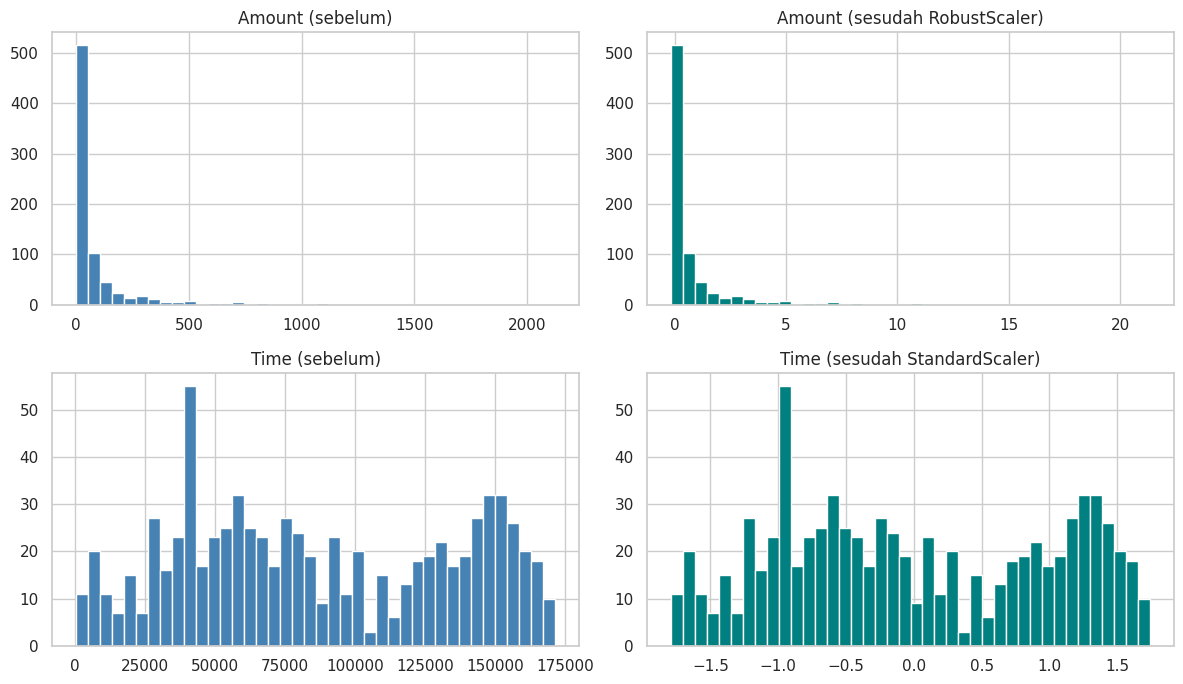

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].hist(X_train["Amount"], bins=40, color="#4682B4");  axes[0, 0].set_title("Amount (sebelum)")
axes[0, 1].hist(X_train_scaled["Amount"], bins=40, color="teal"); axes[0, 1].set_title("Amount (sesudah RobustScaler)")
axes[1, 0].hist(X_train["Time"], bins=40, color="#4682B4");    axes[1, 0].set_title("Time (sebelum)")
axes[1, 1].hist(X_train_scaled["Time"], bins=40, color="teal"); axes[1, 1].set_title("Time (sesudah StandardScaler)")
plt.tight_layout()
plt.show()

## 4.4 Verifikasi Bebas Kebocoran Data

In [20]:
# Pastikan tidak ada baris identik antara data latih dan data uji
gabungan = pd.concat([X_train, X_test])
print(f"Baris identik antara latih dan uji : {gabungan.duplicated().sum()}")
print(f"Indeks latih dan uji saling lepas  : {set(X_train.index).isdisjoint(set(X_test.index))}")
print(f"Missing value pada data latih/uji  : {X_train_scaled.isnull().sum().sum()} / {X_test_scaled.isnull().sum().sum()}")

Baris identik antara latih dan uji : 0
Indeks latih dan uji saling lepas  : True
Missing value pada data latih/uji  : 0 / 0


## 4.5 Menyimpan Hasil

In [21]:
df_clean.to_csv("creditcard_1000_clean.csv", index=False)

train_final = X_train_scaled.assign(Class=y_train.values)
test_final = X_test_scaled.assign(Class=y_test.values)
train_final.to_csv("train_preprocessed.csv", index=False)
test_final.to_csv("test_preprocessed.csv", index=False)

print("File tersimpan:")
print("- creditcard_1000_clean.csv  (data bersih sebelum split/scaling)")
print("- train_preprocessed.csv     (data latih, sudah diskalakan)")
print("- test_preprocessed.csv      (data uji, sudah diskalakan)")

File tersimpan:
- creditcard_1000_clean.csv  (data bersih sebelum split/scaling)
- train_preprocessed.csv     (data latih, sudah diskalakan)
- test_preprocessed.csv      (data uji, sudah diskalakan)


# 5. Ringkasan

In [22]:
print("RINGKASAN PROSES")
print("-" * 50)
print(f"Data awal (dataset kerja)     : {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Missing value ditemukan       : {df.isnull().sum().sum()}")
print(f"Duplikat dihapus              : {df.shape[0] - df_clean.shape[0]}")
print(f"Data bersih                   : {df_clean.shape[0]} baris "
      f"(normal {(df_clean['Class'] == 0).sum()}, fraud {(df_clean['Class'] == 1).sum()})")
print(f"Outlier                       : dipertahankan, Amount ditangani dengan RobustScaler")
print(f"Data latih / uji              : {len(X_train)} / {len(X_test)} (stratified, random_state={RANDOM_STATE})")

RINGKASAN PROSES
--------------------------------------------------
Data awal (dataset kerja)     : 1000 baris, 31 kolom
Missing value ditemukan       : 0
Duplikat dihapus              : 19
Data bersih                   : 981 baris (normal 508, fraud 473)
Outlier                       : dipertahankan, Amount ditangani dengan RobustScaler
Data latih / uji              : 784 / 197 (stratified, random_state=42)


**Kesimpulan**

1. Dataset tidak memiliki missing value, tetapi memiliki baris duplikat (seluruhnya pada kelas fraud) dan banyak kandidat outlier, terutama pada `Amount` dan beberapa fitur PCA.
2. Duplikat dihapus untuk mencegah kebocoran data antara data latih dan uji, sedangkan outlier dan transaksi `Amount = 0` dipertahankan karena dapat merupakan sinyal fraud.
3. `Amount` diskalakan dengan `RobustScaler` dan `Time` dengan `StandardScaler`, dengan scaler di-*fit* hanya pada data latih.
4. Data dibagi secara *stratified* (80:20) dan siap digunakan untuk tahap pemodelan.
5. **Catatan penting:** dataset kerja hampir seimbang karena hasil pengambilan seluruh fraud dan sebagian transaksi normal. Pada kondisi nyata proporsi fraud sekitar 0,17%, sehingga evaluasi akhir sebaiknya juga diuji pada data dengan proporsi kelas yang realistis.